In [2]:
import pandas as pd
import numpy as np


data = {
    'car_model': ['Sedan A', 'SUV B', 'Hatchback C', 'Sedan A', 'SUV B', 'Hatchback C', 'Sedan A', 'SUV B'],
    'year': [2018, 2020, 2015, 2019, 2022, 2012, 2017, 2021],
    'km_driven': [50000, 30000, 120000, 40000, 15000, 180000, 70000, 25000],
    'engine_cc': [1600, 2500, 1300, 1600, 2000, 1000, 1800, 2400],
    'previous_owners': [1, 1, 3, 1, 1, 4, 2, 1],
    'price': [15000, 28000, 8000, 17000, 35000, 5000, 12000, 30000] 
}

df = pd.DataFrame(data)
print("Row Data")
display(df.head())

Row Data


,car_model,year,km_driven,engine_cc,previous_owners,price
0,Sedan A,2018,50000,1600,1,15000
1,SUV B,2020,30000,2500,1,28000
2,Hatchback C,2015,120000,1300,3,8000
3,Sedan A,2019,40000,1600,1,17000
4,SUV B,2022,15000,2000,1,35000


In [6]:
# Feature Creation : Calculate car age based on the current year (e.g., 2026)

current_year = 2026
df['car_age'] = current_year - df['year']

# Interaction Feature : Average mileage per year
# Cars with higher annual mileage typically experience more wear and tear

df['km_per_year'] = df['km_driven'] / df['car_age']

# Binning / Discretization : Categorize car mileage qualitatively

bins = [0, 50000, 120000, 999999]
labels = ['Low_Mileage', 'Medium_Mileage', 'High_Mileage']
df['mileage_category'] = pd.cut(df['km_driven'], bins=bins, labels=labels)

# Mathematical Transformation : Apply logarithm to the price variable for distribution normalization
# This helps linear models perform much better

df['log_price'] = np.log(df['price'])

print("Feature Engineering Data:")
display(df.head())

Feature Engineering Data:


,car_model,year,km_driven,engine_cc,previous_owners,price,car_age,km_per_year,mileage_category,log_price
0,Sedan A,2018,50000,1600,1,15000,8,6250.000000,Low_Mileage,9.615805
1,SUV B,2020,30000,2500,1,28000,6,5000.000000,Low_Mileage,10.239960
2,Hatchback C,2015,120000,1300,3,8000,11,10909.090909,Medium_Mileage,8.987197
3,Sedan A,2019,40000,1600,1,17000,7,5714.285714,Low_Mileage,9.740969
4,SUV B,2022,15000,2000,1,35000,4,3750.000000,Low_Mileage,10.463103


In [4]:
# Preparing For ML :

# One-Hot Encoding:

df_encoded = pd.get_dummies(df, columns=['car_model', 'mileage_category'], drop_first=True)

print('Preparing For ML')
display(df_encoded.head())

Preparing For ML


,year,km_driven,engine_cc,previous_owners,price,car_age,km_per_year,log_price,car_model_SUV B,car_model_Sedan A,mileage_category_Medium_Mileage,mileage_category_High_Mileage
0,2018,50000,1600,1,15000,8,6250.000000,9.615805,False,True,False,False
1,2020,30000,2500,1,28000,6,5000.000000,10.239960,True,False,False,False
2,2015,120000,1300,3,8000,11,10909.090909,8.987197,False,False,True,False
3,2019,40000,1600,1,17000,7,5714.285714,9.740969,False,True,False,False
4,2022,15000,2000,1,35000,4,3750.000000,10.463103,True,False,False,False


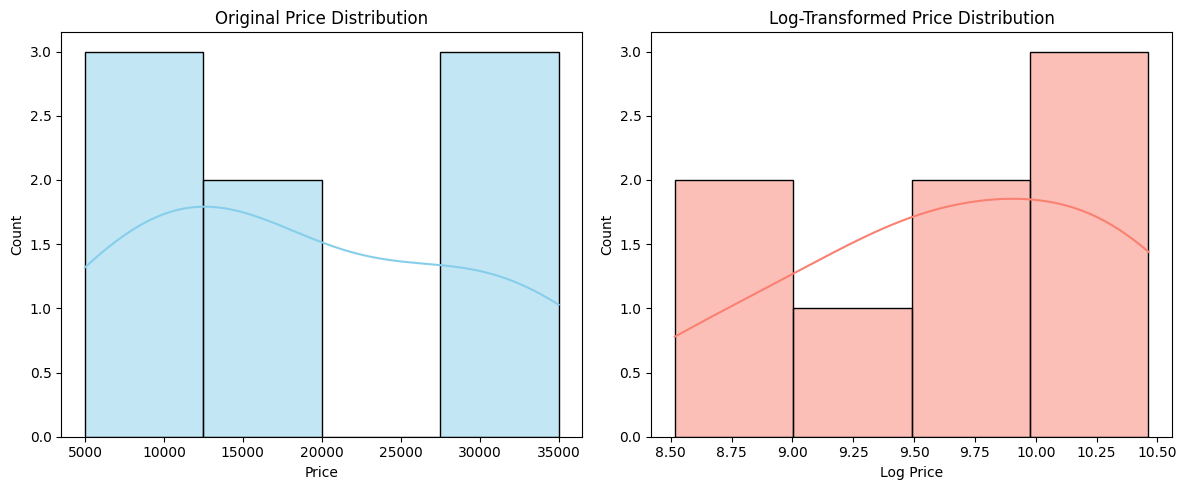

In [7]:
# Data Visualization :

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Original price distribution (skewed) :

sns.histplot(df['price'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Original Price Distribution')
axes[0].set_xlabel('Price')

# Plot 2: Log-transformed price distribution (normalized) :

sns.histplot(df['log_price'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Log-Transformed Price Distribution')
axes[1].set_xlabel('Log Price')

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

df_house = pd.DataFrame({
    'area_sqft': [1200, 2500, 800, 3000, 1500],
    'rooms': [2, 4, 1, 5, 3],
    'build_year': [2010, 2018, 2005, 2022, 2015],
    'price': [150000, 350000, 90000, 500000, 200000]
})

# 1. Feature Creation: Calculate house age based on the current year :

df_house['house_age'] = 2026 - df_house['build_year']

# 2. Interaction Feature: Price per square foot:

df_house['price_per_sqft'] = df_house['price'] / df_house['area_sqft']

# 3. Interaction Feature: Number of rooms relative to total area:

df_house['rooms_per_area'] = df_house['rooms'] / df_house['area_sqft']

# 4. Mathematical Transformation: Apply logarithm to price for distribution normalization:

df_house['log_price'] = np.log(df_house['price'])

display(df_house)

,area_sqft,rooms,build_year,price,house_age,price_per_sqft,rooms_per_area,log_price
0,1200,2,2010,150000,16,125.000000,0.001667,11.918391
1,2500,4,2018,350000,8,140.000000,0.001600,12.765688
2,800,1,2005,90000,21,112.500000,0.001250,11.407565
3,3000,5,2022,500000,4,166.666667,0.001667,13.122363
4,1500,3,2015,200000,11,133.333333,0.002000,12.206073


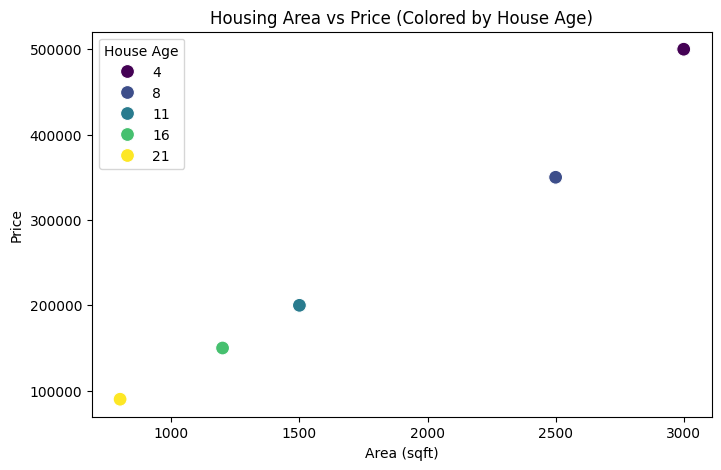

In [ ]:
# Data Visualization :

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_house, x='area_sqft', y='price', hue='house_age', palette='viridis', s=100)
plt.title('Housing Area vs Price (Colored by House Age)')
plt.xlabel('Area (sqft)')
plt.ylabel('Price')
plt.legend(title='House Age')
plt.show()

In [ ]:
import pandas as pd

df_hotel = pd.DataFrame({
    'lead_time': [10, 150, 45, 2, 300],
    'stays_in_weekend_nights': [0, 2, 1, 0, 4],
    'stays_in_week_nights': [1, 5, 3, 1, 10],
    'is_canceled': [0, 1, 0, 0, 1]
})

# 1. Feature Creation: Calculate total stay duration :

df_hotel['total_nights'] = df_hotel['stays_in_weekend_nights'] + df_hotel['stays_in_week_nights']

# 2. Interaction Feature: Ratio of weekend nights to total stay :

df_hotel['weekend_ratio'] = df_hotel['stays_in_weekend_nights'] / (df_hotel['total_nights'] + 1)

# 3. Binning / Discretization: Categorize lead time into booking windows :

df_hotel['lead_time_category'] = pd.cut(df_hotel['lead_time'], bins=[-1, 7, 30, 365], labels=['Last_Minute', 'Short_Term', 'Long_Term'])

display(df_hotel)

,lead_time,stays_in_weekend_nights,stays_in_week_nights,is_canceled,total_nights,weekend_ratio,lead_time_category
0,10,0,1,0,1,0.000000,Short_Term
1,150,2,5,1,7,0.250000,Long_Term
2,45,1,3,0,4,0.200000,Long_Term
3,2,0,1,0,1,0.000000,Last_Minute
4,300,4,10,1,14,0.266667,Long_Term


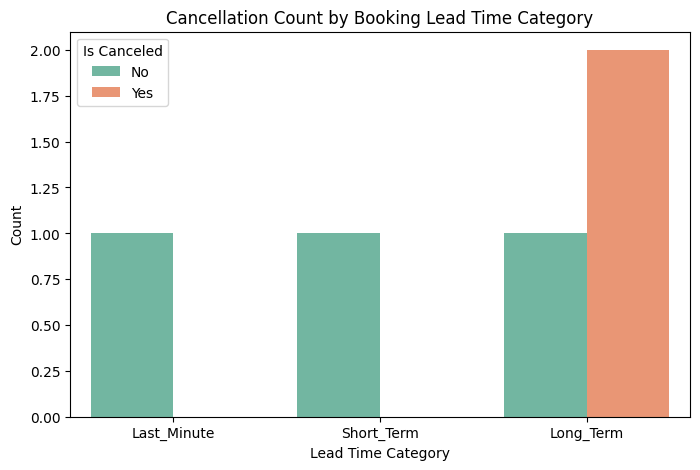

In [ ]:
# Data Visualization :

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.countplot(data=df_hotel, x='lead_time_category', hue='is_canceled', palette='Set2')
plt.title('Cancellation Count by Booking Lead Time Category')
plt.xlabel('Lead Time Category')
plt.ylabel('Count')
plt.legend(title='Is Canceled', labels=['No', 'Yes'])
plt.show()

In [ ]:
# 4. Encoding: Convert categorical lead time feature into numerical dummy variables :

df_hotel = pd.get_dummies(df_hotel, columns=['lead_time_category'], drop_first=True)

display(df_hotel)

,lead_time,stays_in_weekend_nights,stays_in_week_nights,is_canceled,total_nights,weekend_ratio,lead_time_category_Short_Term,lead_time_category_Long_Term
0,10,0,1,0,1,0.000000,True,False
1,150,2,5,1,7,0.250000,False,True
2,45,1,3,0,4,0.200000,False,True
3,2,0,1,0,1,0.000000,False,False
4,300,4,10,1,14,0.266667,False,True


In [4]:
import pandas as pd
import numpy as np

df_bank = pd.DataFrame({
    'customer_id': [101, 101, 102, 102, 103],
    'transaction_amount': [50, 1200, 200, 210, 4500],
    'account_balance': [5000, 4800, 1500, 1300, 5000]
})

# 1. Interaction Feature: Ratio of transaction amount to account balance :

df_bank['amount_to_balance_ratio'] = df_bank['transaction_amount'] / df_bank['account_balance']

# 2. Mathematical Transformation: Apply logarithm to transaction amount to handle skewness :

df_bank['log_amount'] = np.log(df_bank['transaction_amount'])

# 3. Aggregation Feature: Calculate average transaction amount per customer :

avg_amount = df_bank.groupby('customer_id')['transaction_amount'].transform('mean')

# 4. Feature Creation: Difference between current transaction and customer's average :

df_bank['diff_from_customer_avg'] = df_bank['transaction_amount'] - avg_amount

display(df_bank)

,customer_id,transaction_amount,account_balance,amount_to_balance_ratio,log_amount,diff_from_customer_avg
0,101,50,5000,0.010000,3.912023,-575.0
1,101,1200,4800,0.250000,7.090077,575.0
2,102,200,1500,0.133333,5.298317,-5.0
3,102,210,1300,0.161538,5.347108,5.0
4,103,4500,5000,0.900000,8.411833,0.0


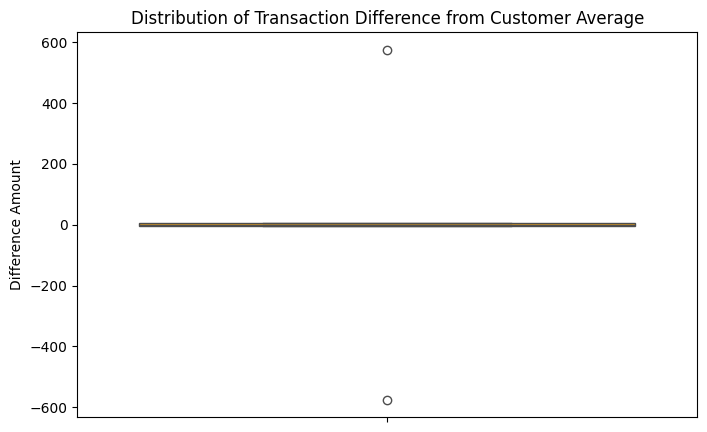

In [ ]:
# Data Visualization :

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(y=df_bank['diff_from_customer_avg'], color='orange')
plt.title('Distribution of Transaction Difference from Customer Average')
plt.ylabel('Difference Amount')
plt.show()